# Лабораторная работа 5. Обработка текста

Датасет: `datasets/sms_spam.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('sms_spam.csv')
df.head(10)

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


# Задание 1
Разбейте предложения на слова. С помощью TF-IDF преобразуйте текст в вектор.

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder

In [4]:
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df['text'])
y = LabelEncoder().fit_transform(df['label'])
X.shape, y.shape, vectorizer.get_feature_names_out()[-10:]

((5574, 8713),
 (5574,),
 array(['zhong', 'zindgi', 'zoe', 'zogtorius', 'zoom', 'zouk', 'zyada',
        'èn', 'ú1', '〨ud'], dtype=object))

# Задние 2.

Выберите 2 метода из 3 (XGBoost, LightGBM, CatBoost). Обучите модели, оцените гиперпараметры. Для каждой модели посчитайте Accuracy, Precision, Recall, F1-score. Постройте confusion matrix и roc-кривую.

In [5]:
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8)

xgb = XGBClassifier()
xgb.fit(X_train, y_train)

catboost = CatBoostClassifier()
catboost.fit(X_train, y_train)

lgbm = LGBMClassifier()
lgbm.fit(X_train, y_train)

Learning rate set to 0.019506
0:	learn: 0.6713484	total: 73.2ms	remaining: 1m 13s
1:	learn: 0.6518180	total: 89.5ms	remaining: 44.7s
2:	learn: 0.6300891	total: 108ms	remaining: 35.9s
3:	learn: 0.6103294	total: 124ms	remaining: 31s
4:	learn: 0.5903977	total: 142ms	remaining: 28.3s
5:	learn: 0.5726404	total: 160ms	remaining: 26.6s
6:	learn: 0.5578040	total: 178ms	remaining: 25.2s
7:	learn: 0.5425209	total: 193ms	remaining: 23.9s
8:	learn: 0.5269487	total: 208ms	remaining: 22.9s
9:	learn: 0.5114428	total: 223ms	remaining: 22.1s
10:	learn: 0.4966185	total: 237ms	remaining: 21.3s
11:	learn: 0.4813474	total: 253ms	remaining: 20.8s
12:	learn: 0.4695906	total: 273ms	remaining: 20.8s
13:	learn: 0.4558641	total: 290ms	remaining: 20.5s
14:	learn: 0.4423657	total: 307ms	remaining: 20.2s
15:	learn: 0.4307415	total: 323ms	remaining: 19.8s
16:	learn: 0.4205515	total: 338ms	remaining: 19.6s
17:	learn: 0.4112417	total: 354ms	remaining: 19.3s
18:	learn: 0.4019416	total: 370ms	remaining: 19.1s
19:	learn:

,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


,MODEL,accuracy,precision,recall,f1_score,roc_auc
0,XGBoost,0.989238,0.969697,0.941176,0.955224,0.968545
1,CatBoost,0.988341,0.984252,0.919118,0.950570,0.958537
2,LightGBM,0.989238,0.969697,0.941176,0.955224,0.968545


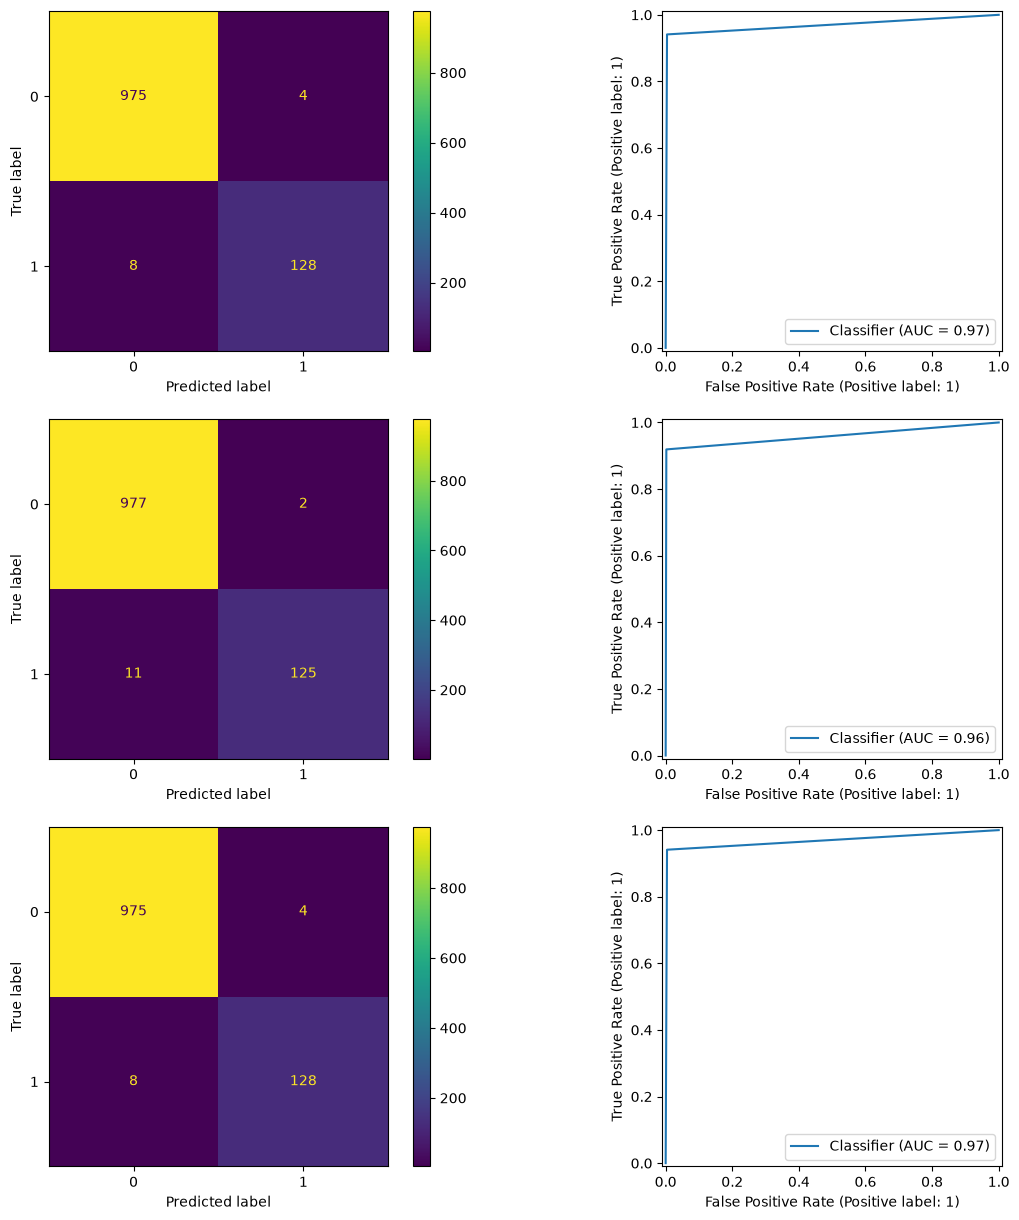

In [7]:
rows = []
figs, axis = plt.subplots(3, 2, figsize=(14, 15))
for name, model, ax in [("XGBoost", xgb, axis[0]), ("CatBoost", catboost, axis[1]), ("LightGBM", lgbm, axis[2])]:
    y_pred = model.predict(X_test)
    rows.append({
        "MODEL": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "f1_score": f1_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_pred),
    })
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax[0])
    RocCurveDisplay.from_predictions(y_test, y_pred, ax=ax[1])

df_metrics = pd.DataFrame(rows)
df_metrics

# Задание 3.
Датасет: `datasets/crime_and_punishment.txt`. Необходимо построить вероятностную модель языка по тексту. Для этого используйте двух-граммную, трех-граммную и четырех-граммную модель. Сгенерируйте текст из 100 слов с помощью получившихся моделей.

In [8]:
from pathlib import Path
import re
from razdel import sentenize
from nltk.lm import Laplace, MLE
from nltk.lm.preprocessing import padded_everygram_pipeline

# 1. Загружаем текст романа
text = Path("crime_and_punishment.txt").read_text(
    encoding="utf-8"
)

def tokenize_words(text):
    # Оставляем только слова и числа, без пунктуации
    return re.findall(r"[^\W_]+", text.lower(), flags=re.UNICODE)


sentences = [
    tokenize_words(sentence.text)
    for sentence in sentenize(text)
]

sentences = [sentence for sentence in sentences if sentence]

# 3. Обучаем n-граммную модель заданного порядка
def train_model(order, sentences):
    train_data, vocab_data = padded_everygram_pipeline(
        order, sentences
    )

    model = Laplace(order)
    model.fit(train_data, vocab_data)

    return model

# 4. Строим биграммную, триграммную и 4-граммную модели
models = {
    n: train_model(n, sentences)
    for n in (2, 3, 4)
}

print("Обучение завершено!")
print("Размер словаря:", len(models[2].vocab))

Обучение завершено!
Размер словаря: 24944


In [9]:
import random
import re


def generate_text(model, order, seed_text, n_words=100):
    # Убираем пунктуацию также из исходного фрагмента
    seed_tokens = tokenize_words(seed_text)

    if not seed_tokens:
        raise ValueError("Начальный текст не должен быть пустым")

    context = seed_tokens[-(order - 1):]

    rng = random.Random(42)
    generated = []
    attempts = 0

    while len(generated) < n_words and attempts < n_words * 30:
        token = model.generate(
            1,
            text_seed=context,
            random_seed=rng
        )
        attempts += 1

        # Обрабатываем границы предложений
        if token in {"<s>", "</s>"}:
            context = ["<s>"] * (order - 1)
            continue

        # Пропускаем неизвестные токены и пунктуацию
        if token == "<UNK>" or not re.fullmatch(
            r"[^\W_]+", token, flags=re.UNICODE
        ):
            continue

        generated.append(token)

        # Обновляем контекст для следующего предсказания
        context = (context + [token])[-(order - 1):]

    return " ".join(generated), len(generated)

In [10]:

seed_text = """
Она тоже весь этот день была в волнении, а в ночь даже опять захворала. Но она была до того счастлива, что почти испугалась своего счастья. Семь лет, только семь лет! В начале своего счастия, в иные мгновения, они оба готовы были смотреть на эти семь лет, как на семь дней. Он даже и не знал того, что новая жизнь не даром же ему достается, что ее надо еще дорого купить, заплатить за нее великим, будущим подвигом...
"""

for n, model in models.items():
    continuation, word_count = generate_text(
        model=model,
        order=n,
        seed_text=seed_text,
        n_words=100
    )

    print(f"\n{'=' * 20} {n}-граммная модель {'=' * 20}")
    print(continuation)
    print(f"\nКоличество сгенерированных слов: {word_count}")



==================== 2-граммная модель ====================
а завтра вся разодетая в улыбке мужа да марфа говорит ей разные подробности всех подтвердила что соня раздельно и гордился что к генералу и так плохо теперь пуще же этак застрелиться пожалуй себя подавила горловую спазму пресекшую в иване великом тридцать копеек за пять лебезятников имел вид его у ней она всё совершенно даже лучше что помирает закричал порфирий протянув ему даже бредить если бы чай через коридор из комнаты так ли даже и пересел машинально повторил свое место где я не верь отвечал дмитрий прокофьич сказал он было катерина то о чем то пульхерия александровна молча ерошил пальцами надо

Количество сгенерированных слов: 100

==================== 3-граммная модель ====================
а завтра ко мне приходи в одно мгновение в чудовищные размеры и что она дочь надворного советника и кавалера а следовательно и пришлось бы ведь это почти обидно ну что ж отвечает катерина ивановна также ни слова даже как будто гулянь